# Credit Card Fraud Detection Using Machine Learning

## Notebook 05: Data Drift Analysis

## 1. Loading Processed Datasets and Inspecting Feature Information

Data drift analysis examines whether the distribution of input features changes between the training period and later transaction periods.

In this notebook, the processed training, validation, and test datasets generated in Notebook 2 will be compared to identify potential changes in feature distributions over time.

The training dataset represents January and February 2026, the validation dataset represents March 2026, and the test dataset represents April to June 2026.

The analysis will help identify features whose distributions have changed and assess potential implications for the reliability of the trained fraud detection models.

In [1]:
import pandas as pd
from pathlib import Path

processed_folder = Path(
    r"C:\Users\Lenovo\Documents\PROJECTS\Final Project - Knovista\Credit_Card_Fraud_Detection\Data\processed"
)

train_df = pd.read_csv(processed_folder / "train_processed.csv")
validation_df = pd.read_csv(processed_folder / "validation_processed.csv")
test_df = pd.read_csv(processed_folder / "test_processed.csv")

feature_names_df = pd.read_csv(
    processed_folder / "expanded_feature_names.csv"
)

print("DATASET DIMENSIONS")
print("=" * 50)

print("Training:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)
print("Feature names:", feature_names_df.shape)

DATASET DIMENSIONS
Training: (38476, 102)
Validation: (20141, 102)
Test: (59490, 102)
Feature names: (99, 2)


In [2]:
# Inspect Expanded Feature Information

print("EXPANDED FEATURE NAMES")
print("=" * 60)

display(feature_names_df.head(10))

print("\nFEATURE NAME FILE COLUMNS:")
print(feature_names_df.columns.tolist())

print("\nDATA TYPES IN TRAINING DATA:")
print(train_df.dtypes.value_counts())

print("\nTOTAL PREDICTOR FEATURES:", len(feature_names_df))

EXPANDED FEATURE NAMES


,Feature_Index,Processed_Feature
0,0,binary__card_present
1,1,binary__international_transaction
2,2,binary__high_risk_country
3,3,binary__used_chip
4,4,binary__used_pin
5,5,binary__device_change_7d
6,6,binary__billing_shipping_mismatch
7,7,binary__account_profile_change_7d
8,8,binary__pos_entry_fallback
9,9,count_log__transactions_last_1h



FEATURE NAME FILE COLUMNS:
['Feature_Index', 'Processed_Feature']

DATA TYPES IN TRAINING DATA:
float64    99
int64       2
str         1
Name: count, dtype: int64

TOTAL PREDICTOR FEATURES: 99


In [3]:

# Identify Predictor Features

feature_columns = feature_names_df["Processed_Feature"].tolist()

print("TOTAL PREDICTOR FEATURES:", len(feature_columns))

print("\nCHECKING FEATURE COLUMNS")
print("=" * 60)

print("All features exist in training:",
      all(col in train_df.columns for col in feature_columns))

print("All features exist in validation:",
      all(col in validation_df.columns for col in feature_columns))

print("All features exist in test:",
      all(col in test_df.columns for col in feature_columns))

print("\nNON-PREDICTOR COLUMNS:")
print([col for col in train_df.columns if col not in feature_columns])

print("\nPREDICTOR DATA TYPES:")
print(train_df[feature_columns].dtypes.value_counts())


TOTAL PREDICTOR FEATURES: 99

CHECKING FEATURE COLUMNS
All features exist in training: True
All features exist in validation: True
All features exist in test: True

NON-PREDICTOR COLUMNS:
['source_row_index', 'is_fraud', 'fraud_type']

PREDICTOR DATA TYPES:
float64    99
Name: count, dtype: int64


In [4]:

# Inspect Unique Values in Predictor Features

unique_counts = train_df[feature_columns].nunique()

print("FEATURE UNIQUE VALUE COUNTS")
print("=" * 60)

print(unique_counts.value_counts().sort_index())

print("\nFEATURES WITH 2 UNIQUE VALUES:")
print(unique_counts[unique_counts == 2].index.tolist())

print("\nFEATURES WITH MORE THAN 2 UNIQUE VALUES:",
      (unique_counts > 2).sum())


FEATURE UNIQUE VALUE COUNTS
2        79
3         1
5         1
8         1
9         2
10        2
16        1
20        1
21        1
22        1
73        1
404       1
816       1
3683      1
6374      1
6785      1
10859     1
16920     1
21460     1
Name: count, dtype: int64

FEATURES WITH 2 UNIQUE VALUES:
['binary__card_present', 'binary__international_transaction', 'binary__high_risk_country', 'binary__used_chip', 'binary__used_pin', 'binary__device_change_7d', 'binary__billing_shipping_mismatch', 'binary__account_profile_change_7d', 'binary__pos_entry_fallback', 'amount_indicator__amount_last_24h_active', 'temporal__month', 'merchant_category_cash_withdrawal', 'merchant_category_digital_goods', 'merchant_category_electronics', 'merchant_category_fuel', 'merchant_category_grocery', 'merchant_category_health', 'merchant_category_restaurant', 'merchant_category_retail', 'merchant_category_subscription', 'merchant_category_travel', 'merchant_country_BR', 'merchant_country_CA', 'me

In [5]:

# Verify Binary and Non-Binary Features

binary_value_features = [
    col for col in feature_columns
    if set(train_df[col].dropna().unique()).issubset({0, 1})
]

two_value_nonbinary = [
    col for col in feature_columns
    if train_df[col].nunique() == 2 and col not in binary_value_features
]

print("FEATURES CONTAINING ONLY 0 AND 1:",
      len(binary_value_features))

print("\nTWO-VALUE FEATURES THAT ARE NOT BINARY:")
print(two_value_nonbinary)

print("\nFEATURES WITH MORE THAN TWO UNIQUE VALUES:",
      sum(train_df[col].nunique() > 2 for col in feature_columns))


FEATURES CONTAINING ONLY 0 AND 1: 78

TWO-VALUE FEATURES THAT ARE NOT BINARY:
['temporal__month']

FEATURES WITH MORE THAN TWO UNIQUE VALUES: 20


In [6]:

# Separate Binary and Numerical Features

numerical_features = [
    col for col in feature_columns
    if col not in binary_value_features
]

print("BINARY FEATURES:", len(binary_value_features))
print("NUMERICAL FEATURES:", len(numerical_features))

print("\nNUMERICAL FEATURE NAMES:")
print(numerical_features)


BINARY FEATURES: 78
NUMERICAL FEATURES: 21

NUMERICAL FEATURE NAMES:
['count_log__transactions_last_1h', 'count_log__transactions_last_24h', 'count_log__failed_auth_attempts_24h', 'count_log__merchant_velocity_24h', 'count_log__pin_retry_count_24h', 'count_original__num_cards_held', 'count_original__transactions_last_7d', 'count_original__num_declined_last_30d', 'continuous_log__transaction_amount', 'continuous_log__credit_limit', 'continuous_log__distance_from_home_km', 'continuous_log__distance_from_last_tx_km', 'continuous_log__amount_vs_avg_ratio', 'continuous_log__account_age_days', 'continuous_original__customer_age', 'continuous_original__credit_score', 'amount_log__amount_last_24h_log1p', 'hour_cyclical__transaction_hour_sin', 'hour_cyclical__transaction_hour_cos', 'temporal__month', 'temporal__week_of_year']


## 2. Binary Feature Distribution Analysis

In [7]:

# Compare Binary Feature Distributions Across Periods

binary_drift = pd.DataFrame({
    "Feature": binary_value_features,
    "Train_Rate": train_df[binary_value_features].mean().values,
    "Validation_Rate": validation_df[binary_value_features].mean().values,
    "Test_Rate": test_df[binary_value_features].mean().values
})

binary_drift["Train_vs_Validation_Change"] = (
    binary_drift["Validation_Rate"] - binary_drift["Train_Rate"]
).abs()

binary_drift["Train_vs_Test_Change"] = (
    binary_drift["Test_Rate"] - binary_drift["Train_Rate"]
).abs()

print("BINARY FEATURE DISTRIBUTION COMPARISON")
print("=" * 70)

display(binary_drift.head(15))


BINARY FEATURE DISTRIBUTION COMPARISON


,Feature,Train_Rate,Validation_Rate,Test_Rate,Train_vs_Validation_Change,Train_vs_Test_Change
0,binary__card_present,0.487759,0.487960,0.488637,0.000201,0.000878
1,binary__international_transaction,0.114903,0.116032,0.122710,0.001129,0.007807
2,binary__high_risk_country,0.064690,0.065836,0.067104,0.001146,0.002414
3,binary__used_chip,0.375065,0.374013,0.378669,0.001052,0.003604
4,binary__used_pin,0.312662,0.314036,0.320340,0.001374,0.007677
5,binary__device_change_7d,0.080596,0.077255,0.149571,0.003340,0.068976
6,binary__billing_shipping_mismatch,0.061025,0.060374,0.065423,0.000651,0.004398
7,binary__account_profile_change_7d,0.050161,0.045777,0.044360,0.004384,0.005801
8,binary__pos_entry_fallback,0.186584,0.183457,0.183930,0.003127,0.002654
9,amount_indicator__amount_last_24h_active,0.022144,0.020605,0.022189,0.001539,0.000045


In [8]:

# Identify Binary Features with the Largest Test-Period Changes

largest_binary_shifts = binary_drift.sort_values(
    by="Train_vs_Test_Change",
    ascending=False
)

print("TOP 15 BINARY FEATURES WITH LARGEST TRAIN-TEST CHANGES")
print("=" * 80)

display(largest_binary_shifts.head(15))


TOP 15 BINARY FEATURES WITH LARGEST TRAIN-TEST CHANGES


,Feature,Train_Rate,Validation_Rate,Test_Rate,Train_vs_Validation_Change,Train_vs_Test_Change
5,binary__device_change_7d,0.080596,0.077255,0.149571,0.003340,0.068976
32,transaction_day_of_week_Friday,0.152225,0.129537,0.140377,0.022688,0.011848
36,transaction_day_of_week_Thursday,0.153862,0.131324,0.143234,0.022538,0.010628
35,transaction_day_of_week_Sunday,0.135175,0.158731,0.144411,0.023556,0.009236
34,transaction_day_of_week_Saturday,0.149028,0.132317,0.140763,0.016711,0.008265
38,transaction_day_of_week_Wednesday,0.136033,0.125863,0.144024,0.010170,0.007991
1,binary__international_transaction,0.114903,0.116032,0.122710,0.001129,0.007807
4,binary__used_pin,0.312662,0.314036,0.320340,0.001374,0.007677
33,transaction_day_of_week_Monday,0.135175,0.160618,0.142679,0.025442,0.007504
72,email_domain_gmail.com,0.300863,0.296212,0.294671,0.004651,0.006192


## 3. Numerical Feature Profiling and PSI Calculation

In [9]:

# Inspect Numerical Feature Distributions

numerical_summary = pd.DataFrame({
    "Train_Mean": train_df[numerical_features].mean(),
    "Validation_Mean": validation_df[numerical_features].mean(),
    "Test_Mean": test_df[numerical_features].mean(),
    "Train_Std": train_df[numerical_features].std(),
    "Train_Min": train_df[numerical_features].min(),
    "Train_Median": train_df[numerical_features].median(),
    "Train_Max": train_df[numerical_features].max()
})

print("NUMERICAL FEATURE DISTRIBUTION SUMMARY")
print("=" * 80)

display(numerical_summary)


NUMERICAL FEATURE DISTRIBUTION SUMMARY


,Train_Mean,Validation_Mean,Test_Mean,Train_Std,Train_Min,Train_Median,Train_Max
count_log__transactions_last_1h,8.199422e-17,0.016565,0.033959,1.000013,-0.218547,-2.185467e-01,8.211620
count_log__transactions_last_24h,2.012921e-17,0.000666,0.013325,1.000013,-0.293712,-2.937115e-01,6.304469
count_log__failed_auth_attempts_24h,3.037849e-17,0.005171,0.120089,1.000013,-0.390898,-3.908978e-01,6.576075
count_log__merchant_velocity_24h,8.051685e-17,-0.000994,0.005463,1.000013,-0.434369,-4.343694e-01,6.125947
count_log__pin_retry_count_24h,4.949201e-17,0.007234,-0.006925,1.000013,-0.286994,-2.869940e-01,7.936832
count_original__num_cards_held,7.091392e-17,-0.009953,-0.013727,1.000013,-1.361817,1.277151e-01,3.851546
count_original__transactions_last_7d,-3.988908e-17,0.020526,0.019221,1.000013,-0.381428,-3.814282e-01,9.964592
count_original__num_declined_last_30d,-8.864240e-18,0.028051,0.015674,1.000013,-0.110640,-1.106397e-01,17.738304
continuous_log__transaction_amount,-1.233607e-16,0.000441,-0.024066,1.000013,-3.749631,-2.163608e-02,4.611437
continuous_log__credit_limit,2.336097e-15,-0.014441,-0.006638,1.000013,-3.261857,9.099238e-03,3.688421


In [10]:

# Check Numerical Feature Characteristics

numerical_checks = pd.DataFrame({
    "Unique_Values": train_df[numerical_features].nunique(),
    "Zero_Count": (train_df[numerical_features] == 0).sum(),
    "Zero_Percentage": (
        (train_df[numerical_features] == 0).mean() * 100
    ),
    "Train_25th_Percentile": train_df[numerical_features].quantile(0.25),
    "Train_Median": train_df[numerical_features].median(),
    "Train_75th_Percentile": train_df[numerical_features].quantile(0.75)
})

print("NUMERICAL FEATURE CHARACTERISTICS")
print("=" * 80)

display(numerical_checks)


NUMERICAL FEATURE CHARACTERISTICS


,Unique_Values,Zero_Count,Zero_Percentage,Train_25th_Percentile,Train_Median,Train_75th_Percentile
count_log__transactions_last_1h,9,0,0.000000,-0.218547,-2.185467e-01,-0.218547
count_log__transactions_last_24h,21,0,0.000000,-0.293712,-2.937115e-01,-0.293712
count_log__failed_auth_attempts_24h,10,0,0.000000,-0.390898,-3.908978e-01,-0.390898
count_log__merchant_velocity_24h,16,0,0.000000,-0.434369,-4.343694e-01,-0.434369
count_log__pin_retry_count_24h,10,0,0.000000,-0.286994,-2.869940e-01,-0.286994
count_original__num_cards_held,8,0,0.000000,-0.617051,1.277151e-01,0.872481
count_original__transactions_last_7d,5,0,0.000000,-0.381428,-3.814282e-01,-0.381428
count_original__num_declined_last_30d,3,0,0.000000,-0.110640,-1.106397e-01,-0.110640
continuous_log__transaction_amount,10859,0,0.000000,-0.691758,-2.163608e-02,0.668746
continuous_log__credit_limit,21460,0,0.000000,-0.668256,9.099238e-03,0.670316


In [11]:

# Separate Numerical Features by Distribution Characteristics

cyclical_features = [
    "hour_cyclical__transaction_hour_sin",
    "hour_cyclical__transaction_hour_cos"
]

zero_inflated_features = [
    "amount_log__amount_last_24h_log1p"
]

low_cardinality_features = [
    col for col in numerical_features
    if train_df[col].nunique() <= 30
    and col not in cyclical_features
]

continuous_features = [
    col for col in numerical_features
    if col not in low_cardinality_features
    and col not in cyclical_features
    and col not in zero_inflated_features
]

print("LOW-CARDINALITY FEATURES:", len(low_cardinality_features))
print(low_cardinality_features)

print("\nCONTINUOUS FEATURES:", len(continuous_features))
print(continuous_features)

print("\nZERO-INFLATED FEATURES:", len(zero_inflated_features))
print(zero_inflated_features)

print("\nCYCLICAL FEATURES:", len(cyclical_features))
print(cyclical_features)

print("\nTOTAL:",
      len(low_cardinality_features)
      + len(continuous_features)
      + len(zero_inflated_features)
      + len(cyclical_features))


LOW-CARDINALITY FEATURES: 10
['count_log__transactions_last_1h', 'count_log__transactions_last_24h', 'count_log__failed_auth_attempts_24h', 'count_log__merchant_velocity_24h', 'count_log__pin_retry_count_24h', 'count_original__num_cards_held', 'count_original__transactions_last_7d', 'count_original__num_declined_last_30d', 'temporal__month', 'temporal__week_of_year']

CONTINUOUS FEATURES: 8
['continuous_log__transaction_amount', 'continuous_log__credit_limit', 'continuous_log__distance_from_home_km', 'continuous_log__distance_from_last_tx_km', 'continuous_log__amount_vs_avg_ratio', 'continuous_log__account_age_days', 'continuous_original__customer_age', 'continuous_original__credit_score']

ZERO-INFLATED FEATURES: 1
['amount_log__amount_last_24h_log1p']

CYCLICAL FEATURES: 2
['hour_cyclical__transaction_hour_sin', 'hour_cyclical__transaction_hour_cos']

TOTAL: 21


In [12]:

# Calculate PSI for Low-Cardinality Features

import numpy as np

def calculate_discrete_psi(expected, actual):
    expected = expected.dropna()
    actual = actual.dropna()

    reference_values = expected.unique()

    expected_proportions = np.array([
        (expected == value).mean()
        for value in reference_values
    ] + [0.0])

    actual_proportions = np.array([
        (actual == value).mean()
        for value in reference_values
    ] + [(~actual.isin(reference_values)).mean()])

    epsilon = 1e-6

    expected_proportions = np.clip(
        expected_proportions, epsilon, None
    )
    actual_proportions = np.clip(
        actual_proportions, epsilon, None
    )

    expected_proportions /= expected_proportions.sum()
    actual_proportions /= actual_proportions.sum()

    return np.sum(
        (actual_proportions - expected_proportions)
        * np.log(actual_proportions / expected_proportions)
    )


low_cardinality_psi = []

for feature in low_cardinality_features:
    low_cardinality_psi.append({
        "Feature": feature,
        "Train_vs_Validation_PSI": calculate_discrete_psi(
            train_df[feature], validation_df[feature]
        ),
        "Train_vs_Test_PSI": calculate_discrete_psi(
            train_df[feature], test_df[feature]
        )
    })

low_cardinality_psi_df = pd.DataFrame(low_cardinality_psi)

print("LOW-CARDINALITY FEATURE PSI RESULTS")
print("=" * 75)

display(low_cardinality_psi_df)


LOW-CARDINALITY FEATURE PSI RESULTS


,Feature,Train_vs_Validation_PSI,Train_vs_Test_PSI
0,count_log__transactions_last_1h,0.000737,0.001204
1,count_log__transactions_last_24h,0.001478,0.001353
2,count_log__failed_auth_attempts_24h,0.001463,0.021568
3,count_log__merchant_velocity_24h,0.001632,0.000682
4,count_log__pin_retry_count_24h,0.000643,0.000230
5,count_original__num_cards_held,0.000429,0.000584
6,count_original__transactions_last_7d,0.000727,0.000434
7,count_original__num_declined_last_30d,0.001662,0.000419
8,temporal__month,26.938967,26.938967
9,temporal__week_of_year,23.866089,25.446169


In [13]:

# Calculate PSI for Continuous Features

def calculate_continuous_psi(expected, actual, bins=10):
    expected = expected.dropna()
    actual = actual.dropna()

    quantile_edges = np.unique(
        expected.quantile(np.linspace(0, 1, bins + 1)).values
    )

    if len(quantile_edges) < 2:
        return np.nan

    bin_edges = quantile_edges.copy()
    bin_edges[0] = -np.inf
    bin_edges[-1] = np.inf

    expected_bins = pd.cut(
        expected, bins=bin_edges, include_lowest=True
    )

    actual_bins = pd.cut(
        actual, bins=bin_edges, include_lowest=True
    )

    expected_proportions = (
        expected_bins.value_counts(sort=False, normalize=True).values
    )

    actual_proportions = (
        actual_bins.value_counts(sort=False, normalize=True).values
    )

    epsilon = 1e-6

    expected_proportions = np.clip(
        expected_proportions, epsilon, None
    )
    actual_proportions = np.clip(
        actual_proportions, epsilon, None
    )

    expected_proportions /= expected_proportions.sum()
    actual_proportions /= actual_proportions.sum()

    return np.sum(
        (actual_proportions - expected_proportions)
        * np.log(actual_proportions / expected_proportions)
    )


continuous_psi = []

for feature in continuous_features:
    continuous_psi.append({
        "Feature": feature,
        "Train_vs_Validation_PSI": calculate_continuous_psi(
            train_df[feature], validation_df[feature]
        ),
        "Train_vs_Test_PSI": calculate_continuous_psi(
            train_df[feature], test_df[feature]
        )
    })

continuous_psi_df = pd.DataFrame(continuous_psi)

print("CONTINUOUS FEATURE PSI RESULTS")
print("=" * 75)

display(continuous_psi_df)


CONTINUOUS FEATURE PSI RESULTS


,Feature,Train_vs_Validation_PSI,Train_vs_Test_PSI
0,continuous_log__transaction_amount,0.000995,0.001575
1,continuous_log__credit_limit,0.001052,0.000631
2,continuous_log__distance_from_home_km,0.000922,0.001282
3,continuous_log__distance_from_last_tx_km,0.000923,0.000241
4,continuous_log__amount_vs_avg_ratio,0.003211,0.002453
5,continuous_log__account_age_days,0.060092,0.336742
6,continuous_original__customer_age,0.000315,0.000162
7,continuous_original__credit_score,0.000661,0.000471


In [14]:

# Analyze Zero-Inflated Feature

zero_feature = "amount_log__amount_last_24h_log1p"

def calculate_zero_positive_psi(expected, actual):
    expected = expected.dropna()
    actual = actual.dropna()

    expected_zero_rate = (expected == 0).mean()
    actual_zero_rate = (actual == 0).mean()

    expected_positive = expected[expected > 0]
    actual_positive = actual[actual > 0]

    zero_psi = calculate_discrete_psi(
        (expected == 0).astype(int),
        (actual == 0).astype(int)
    )

    if len(expected_positive) > 0 and len(actual_positive) > 0:
        positive_psi = calculate_continuous_psi(
            expected_positive,
            actual_positive
        )
    else:
        positive_psi = np.nan

    return {
        "Train_Zero_Rate": expected_zero_rate,
        "Comparison_Zero_Rate": actual_zero_rate,
        "Zero_Rate_PSI": zero_psi,
        "Positive_Value_PSI": positive_psi
    }


zero_feature_validation = calculate_zero_positive_psi(
    train_df[zero_feature],
    validation_df[zero_feature]
)

zero_feature_test = calculate_zero_positive_psi(
    train_df[zero_feature],
    test_df[zero_feature]
)

print("ZERO-INFLATED FEATURE ANALYSIS")
print("=" * 70)

print("\nTRAIN VS VALIDATION:")
print(zero_feature_validation)

print("\nTRAIN VS TEST:")
print(zero_feature_test)


ZERO-INFLATED FEATURE ANALYSIS

TRAIN VS VALIDATION:
{'Train_Zero_Rate': np.float64(0.9778563260214159), 'Comparison_Zero_Rate': np.float64(0.9793952633930788), 'Zero_Rate_PSI': np.float64(0.00011327094735549607), 'Positive_Value_PSI': np.float64(0.025377320992879156)}

TRAIN VS TEST:
{'Train_Zero_Rate': np.float64(0.9778563260214159), 'Comparison_Zero_Rate': np.float64(0.9778113968734241), 'Zero_Rate_PSI': np.float64(9.313243568074149e-08), 'Positive_Value_PSI': np.float64(0.03355166751299926)}


In [15]:

# Calculate PSI for Cyclical Features

def calculate_cyclical_psi(expected, actual, bins=10):
    bin_edges = np.linspace(-1, 1, bins + 1)

    expected_bins = pd.cut(
        expected, bins=bin_edges, include_lowest=True
    )

    actual_bins = pd.cut(
        actual, bins=bin_edges, include_lowest=True
    )

    expected_proportions = (
        expected_bins.value_counts(sort=False, normalize=True).values
    )

    actual_proportions = (
        actual_bins.value_counts(sort=False, normalize=True).values
    )

    epsilon = 1e-6

    expected_proportions = np.clip(
        expected_proportions, epsilon, None
    )
    actual_proportions = np.clip(
        actual_proportions, epsilon, None
    )

    expected_proportions /= expected_proportions.sum()
    actual_proportions /= actual_proportions.sum()

    return np.sum(
        (actual_proportions - expected_proportions)
        * np.log(actual_proportions / expected_proportions)
    )


cyclical_psi = []

for feature in cyclical_features:
    cyclical_psi.append({
        "Feature": feature,
        "Train_vs_Validation_PSI": calculate_cyclical_psi(
            train_df[feature], validation_df[feature]
        ),
        "Train_vs_Test_PSI": calculate_cyclical_psi(
            train_df[feature], test_df[feature]
        )
    })

cyclical_psi_df = pd.DataFrame(cyclical_psi)

print("CYCLICAL FEATURE PSI RESULTS")
print("=" * 75)

display(cyclical_psi_df)


CYCLICAL FEATURE PSI RESULTS


,Feature,Train_vs_Validation_PSI,Train_vs_Test_PSI
0,hour_cyclical__transaction_hour_sin,0.000962,0.000489
1,hour_cyclical__transaction_hour_cos,0.001384,0.000499


In [16]:

# Combine Numerical Feature PSI Results

numerical_psi_df = pd.concat(
    [
        low_cardinality_psi_df,
        continuous_psi_df,
        cyclical_psi_df
    ],
    ignore_index=True
)

zero_psi_row = pd.DataFrame([{
    "Feature": zero_feature,
    "Train_vs_Validation_PSI": zero_feature_validation["Positive_Value_PSI"],
    "Train_vs_Test_PSI": zero_feature_test["Positive_Value_PSI"]
}])

numerical_psi_df = pd.concat(
    [numerical_psi_df, zero_psi_row],
    ignore_index=True
)

print("CONSOLIDATED NUMERICAL FEATURE PSI RESULTS")
print("=" * 85)

display(
    numerical_psi_df.sort_values(
        by="Train_vs_Test_PSI",
        ascending=False
    )
)


CONSOLIDATED NUMERICAL FEATURE PSI RESULTS


,Feature,Train_vs_Validation_PSI,Train_vs_Test_PSI
8,temporal__month,26.938967,26.938967
9,temporal__week_of_year,23.866089,25.446169
15,continuous_log__account_age_days,0.060092,0.336742
20,amount_log__amount_last_24h_log1p,0.025377,0.033552
2,count_log__failed_auth_attempts_24h,0.001463,0.021568
14,continuous_log__amount_vs_avg_ratio,0.003211,0.002453
10,continuous_log__transaction_amount,0.000995,0.001575
1,count_log__transactions_last_24h,0.001478,0.001353
12,continuous_log__distance_from_home_km,0.000922,0.001282
0,count_log__transactions_last_1h,0.000737,0.001204


In [17]:

# Calculate Overall PSI for the Zero-Inflated Feature

def calculate_zero_inflated_psi(expected, actual, bins=10):
    expected = expected.dropna()
    actual = actual.dropna()

    expected_positive = expected[expected > 0]
    actual_positive = actual[actual > 0]

    # Create bin boundaries using positive training values
    quantile_edges = np.unique(
        expected_positive.quantile(
            np.linspace(0, 1, bins + 1)
        ).values
    )

    bin_edges = quantile_edges.copy()
    bin_edges[0] = -np.inf
    bin_edges[-1] = np.inf

    # Calculate positive-value bins
    expected_bins = pd.cut(
        expected_positive, bins=bin_edges, include_lowest=True
    )

    actual_bins = pd.cut(
        actual_positive, bins=bin_edges, include_lowest=True
    )

    expected_positive_rates = (
        expected_bins.value_counts(sort=False).values / len(expected)
    )

    actual_positive_rates = (
        actual_bins.value_counts(sort=False).values / len(actual)
    )

    # Include zero as the first category
    expected_proportions = np.concatenate([
        [(expected == 0).mean()],
        expected_positive_rates
    ])

    actual_proportions = np.concatenate([
        [(actual == 0).mean()],
        actual_positive_rates
    ])

    epsilon = 1e-6

    expected_proportions = np.clip(
        expected_proportions, epsilon, None
    )
    actual_proportions = np.clip(
        actual_proportions, epsilon, None
    )

    expected_proportions /= expected_proportions.sum()
    actual_proportions /= actual_proportions.sum()

    return np.sum(
        (actual_proportions - expected_proportions)
        * np.log(actual_proportions / expected_proportions)
    )


overall_zero_psi_validation = calculate_zero_inflated_psi(
    train_df[zero_feature],
    validation_df[zero_feature]
)

overall_zero_psi_test = calculate_zero_inflated_psi(
    train_df[zero_feature],
    test_df[zero_feature]
)

print("OVERALL ZERO-INFLATED FEATURE PSI")
print("=" * 65)

print("Train vs Validation:", overall_zero_psi_validation)
print("Train vs Test:", overall_zero_psi_test)


OVERALL ZERO-INFLATED FEATURE PSI
Train vs Validation: 0.000655480753652407
Train vs Test: 0.0007437899752672694


In [18]:

# Update Consolidated Numerical PSI Results

numerical_psi_df.loc[
    numerical_psi_df["Feature"] == zero_feature,
    "Train_vs_Validation_PSI"
] = overall_zero_psi_validation

numerical_psi_df.loc[
    numerical_psi_df["Feature"] == zero_feature,
    "Train_vs_Test_PSI"
] = overall_zero_psi_test

print("UPDATED NUMERICAL FEATURE PSI RESULTS")
print("=" * 85)

display(
    numerical_psi_df.sort_values(
        by="Train_vs_Test_PSI",
        ascending=False
    )
)


UPDATED NUMERICAL FEATURE PSI RESULTS


,Feature,Train_vs_Validation_PSI,Train_vs_Test_PSI
8,temporal__month,26.938967,26.938967
9,temporal__week_of_year,23.866089,25.446169
15,continuous_log__account_age_days,0.060092,0.336742
2,count_log__failed_auth_attempts_24h,0.001463,0.021568
14,continuous_log__amount_vs_avg_ratio,0.003211,0.002453
10,continuous_log__transaction_amount,0.000995,0.001575
1,count_log__transactions_last_24h,0.001478,0.001353
12,continuous_log__distance_from_home_km,0.000922,0.001282
0,count_log__transactions_last_1h,0.000737,0.001204
20,amount_log__amount_last_24h_log1p,0.000655,0.000744


## 4. Binary Feature PSI and Consolidated Drift Assessment

In [19]:

# Calculate PSI for Binary Features

binary_psi_results = []

for feature in binary_value_features:
    binary_psi_results.append({
        "Feature": feature,
        "Train_vs_Validation_PSI": calculate_discrete_psi(
            train_df[feature],
            validation_df[feature]
        ),
        "Train_vs_Test_PSI": calculate_discrete_psi(
            train_df[feature],
            test_df[feature]
        )
    })

binary_psi_df = pd.DataFrame(binary_psi_results)

print("BINARY FEATURE PSI RESULTS")
print("=" * 85)

display(
    binary_psi_df.sort_values(
        by="Train_vs_Test_PSI",
        ascending=False
    )
)


BINARY FEATURE PSI RESULTS


,Feature,Train_vs_Validation_PSI,Train_vs_Test_PSI
5,binary__device_change_7d,1.535077e-04,4.802866e-02
32,transaction_day_of_week_Friday,4.260878e-03,1.124499e-03
36,transaction_day_of_week_Thursday,4.162220e-03,8.933738e-04
7,binary__account_profile_change_7d,4.211039e-04,7.481907e-04
35,transaction_day_of_week_Sunday,4.434476e-03,7.095496e-04
...,...,...,...
43,customer_country_BR,1.314426e-04,2.006290e-06
31,merchant_country_US,4.904894e-06,3.121554e-07
9,amount_indicator__amount_last_24h_active,1.132709e-04,9.313244e-08
60,device_type_desktop,9.226441e-07,6.328214e-08


In [20]:

# Combine Binary and Numerical Feature PSI Results

all_feature_psi_df = pd.concat(
    [binary_psi_df, numerical_psi_df],
    ignore_index=True
)

all_feature_psi_df = all_feature_psi_df.sort_values(
    by="Train_vs_Test_PSI",
    ascending=False
).reset_index(drop=True)

print("COMPLETE FEATURE DRIFT SUMMARY")
print("=" * 90)

print("Total features:", len(all_feature_psi_df))
print("Binary features:", len(binary_psi_df))
print("Numerical features:", len(numerical_psi_df))

display(all_feature_psi_df)


COMPLETE FEATURE DRIFT SUMMARY
Total features: 99
Binary features: 78
Numerical features: 21


,Feature,Train_vs_Validation_PSI,Train_vs_Test_PSI
0,temporal__month,2.693897e+01,2.693897e+01
1,temporal__week_of_year,2.386609e+01,2.544617e+01
2,continuous_log__account_age_days,6.009194e-02,3.367418e-01
3,binary__device_change_7d,1.535077e-04,4.802866e-02
4,count_log__failed_auth_attempts_24h,1.462748e-03,2.156844e-02
...,...,...,...
94,customer_country_BR,1.314426e-04,2.006290e-06
95,merchant_country_US,4.904894e-06,3.121554e-07
96,amount_indicator__amount_last_24h_active,1.132709e-04,9.313244e-08
97,device_type_desktop,9.226441e-07,6.328214e-08


In [21]:

# Classify Feature Drift Levels

def classify_psi(value):
    if value < 0.10:
        return "Low"
    elif value <= 0.25:
        return "Moderate"
    else:
        return "High"


all_feature_psi_df["Drift_Level"] = (
    all_feature_psi_df["Train_vs_Test_PSI"].apply(classify_psi)
)

temporal_features = [
    "temporal__month",
    "temporal__week_of_year"
]

all_feature_psi_df["Feature_Group"] = np.where(
    all_feature_psi_df["Feature"].isin(temporal_features),
    "Temporal",
    "Non-Temporal"
)

print("DRIFT LEVEL SUMMARY")
print("=" * 65)

print("\nAll features:")
display(
    all_feature_psi_df["Drift_Level"]
    .value_counts()
    .rename_axis("Drift_Level")
    .reset_index(name="Feature_Count")
)

print("\nNon-temporal features:")
display(
    all_feature_psi_df[
        all_feature_psi_df["Feature_Group"] == "Non-Temporal"
    ]["Drift_Level"]
    .value_counts()
    .rename_axis("Drift_Level")
    .reset_index(name="Feature_Count")
)

print("\nNon-temporal features with highest PSI:")
display(
    all_feature_psi_df[
        all_feature_psi_df["Feature_Group"] == "Non-Temporal"
    ].head(10)
)


DRIFT LEVEL SUMMARY

All features:


,Drift_Level,Feature_Count
0,Low,96
1,High,3



Non-temporal features:


,Drift_Level,Feature_Count
0,Low,96
1,High,1



Non-temporal features with highest PSI:


,Feature,Train_vs_Validation_PSI,Train_vs_Test_PSI,Drift_Level,Feature_Group
2,continuous_log__account_age_days,0.060092,0.336742,High,Non-Temporal
3,binary__device_change_7d,0.000154,0.048029,Low,Non-Temporal
4,count_log__failed_auth_attempts_24h,0.001463,0.021568,Low,Non-Temporal
5,continuous_log__amount_vs_avg_ratio,0.003211,0.002453,Low,Non-Temporal
6,continuous_log__transaction_amount,0.000995,0.001575,Low,Non-Temporal
7,count_log__transactions_last_24h,0.001478,0.001353,Low,Non-Temporal
8,continuous_log__distance_from_home_km,0.000922,0.001282,Low,Non-Temporal
9,count_log__transactions_last_1h,0.000737,0.001204,Low,Non-Temporal
10,transaction_day_of_week_Friday,0.004261,0.001124,Low,Non-Temporal
11,transaction_day_of_week_Thursday,0.004162,0.000893,Low,Non-Temporal


## 5. Investigation of Notable Feature Shifts and Target Distribution

In [22]:

# Investigate Account Age Distribution Shift

account_age_feature = "continuous_log__account_age_days"

account_age_summary = pd.DataFrame({
    "Training": train_df[account_age_feature].describe(),
    "Validation": validation_df[account_age_feature].describe(),
    "Test": test_df[account_age_feature].describe()
})

print("ACCOUNT AGE DISTRIBUTION COMPARISON")
print("=" * 75)

display(
    account_age_summary.loc[
        ["mean", "std", "min", "25%", "50%", "75%", "max"]
    ].round(4)
)


ACCOUNT AGE DISTRIBUTION COMPARISON


,Training,Validation,Test
mean,-0.0000,0.1268,0.2647
std,1.0000,0.9030,0.8086
min,-3.6004,-2.1918,-2.1747
25%,-0.7071,-0.5437,-0.3440
50%,-0.0427,0.0453,0.1659
75%,0.6745,0.7318,0.7821
max,3.9027,4.1226,4.1232


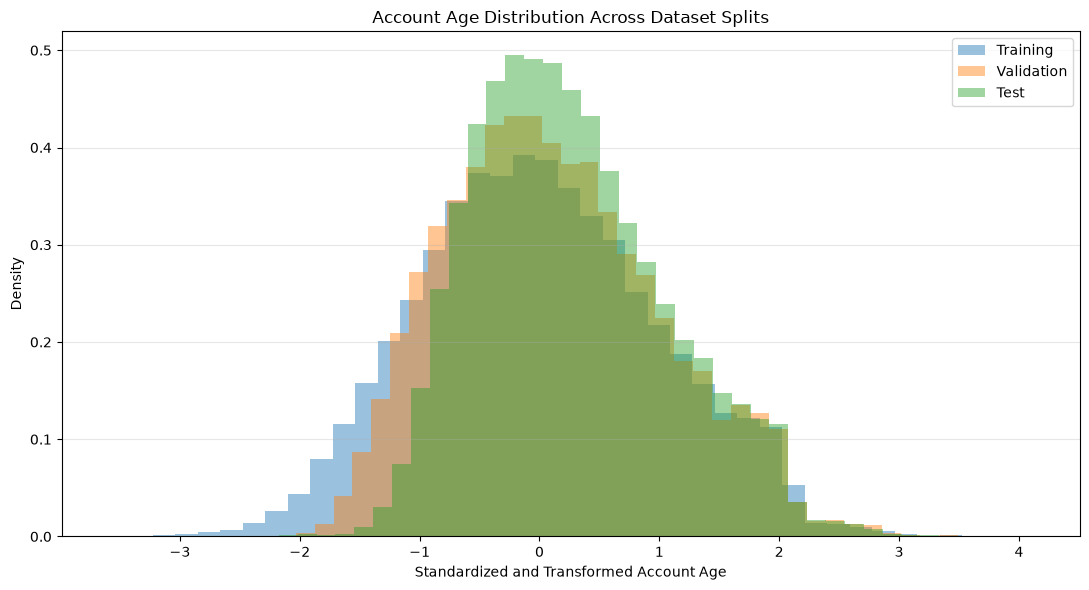

In [23]:

# Visualize Account Age Distribution Across Time Periods

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.hist(
    train_df[account_age_feature],
    bins=40,
    alpha=0.45,
    density=True,
    label="Training"
)

plt.hist(
    validation_df[account_age_feature],
    bins=40,
    alpha=0.45,
    density=True,
    label="Validation"
)

plt.hist(
    test_df[account_age_feature],
    bins=40,
    alpha=0.45,
    density=True,
    label="Test"
)

plt.title("Account Age Distribution Across Dataset Splits")
plt.xlabel("Standardized and Transformed Account Age")
plt.ylabel("Density")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [24]:

# Compare Fraud Type Distribution Across Dataset Splits

target_distribution = pd.DataFrame({
    "Training": train_df["fraud_type"].value_counts(normalize=True),
    "Validation": validation_df["fraud_type"].value_counts(normalize=True),
    "Test": test_df["fraud_type"].value_counts(normalize=True)
}).fillna(0)

target_distribution = target_distribution * 100

print("FRAUD TYPE DISTRIBUTION COMPARISON")
print("=" * 75)

display(target_distribution.round(3))

print("\nBINARY FRAUD RATE COMPARISON")
print("=" * 75)

fraud_rate_comparison = pd.DataFrame({
    "Training": train_df["is_fraud"].mean() * 100,
    "Validation": validation_df["is_fraud"].mean() * 100,
    "Test": test_df["is_fraud"].mean() * 100
}, index=["Fraud Rate (%)"])

display(fraud_rate_comparison.round(3))


FRAUD TYPE DISTRIBUTION COMPARISON


,Training,Validation,Test
fraud_type,,,
Account-Takeover,2.113,2.130,2.234
Card-Not-Present,2.503,2.487,2.379
Card-Present,1.585,1.763,1.568
Legitimate,92.047,92.051,91.876
Synthetic-Identity,1.752,1.569,1.943



BINARY FRAUD RATE COMPARISON


,Training,Validation,Test
Fraud Rate (%),7.953,7.949,8.124


In [25]:

# Quantify Target Distribution Changes

target_psi_results = pd.DataFrame([
    {
        "Target": "fraud_type",
        "Train_vs_Validation_PSI": calculate_discrete_psi(
            train_df["fraud_type"],
            validation_df["fraud_type"]
        ),
        "Train_vs_Test_PSI": calculate_discrete_psi(
            train_df["fraud_type"],
            test_df["fraud_type"]
        )
    },
    {
        "Target": "is_fraud",
        "Train_vs_Validation_PSI": calculate_discrete_psi(
            train_df["is_fraud"],
            validation_df["is_fraud"]
        ),
        "Train_vs_Test_PSI": calculate_discrete_psi(
            train_df["is_fraud"],
            test_df["is_fraud"]
        )
    }
])

print("TARGET DISTRIBUTION PSI")
print("=" * 75)

display(target_psi_results.round(6))


TARGET DISTRIBUTION PSI


,Target,Train_vs_Validation_PSI,Train_vs_Test_PSI
0,fraud_type,0.000391,0.000334
1,is_fraud,0.000000,0.000040


## 6. Saving and Verifying Data Drift Reports

In [26]:

# Save Data Drift Analysis Reports

from pathlib import Path

project_folder = Path(
    r"C:\Users\Lenovo\Documents\PROJECTS\Final Project - Knovista\Credit_Card_Fraud_Detection"
)

reports_folder = project_folder / "reports"
reports_folder.mkdir(parents=True, exist_ok=True)

all_feature_psi_df.to_csv(
    reports_folder / "feature_drift_psi_summary.csv",
    index=False
)

target_psi_results.to_csv(
    reports_folder / "target_distribution_psi.csv",
    index=False
)

binary_drift.to_csv(
    reports_folder / "binary_feature_distribution_changes.csv",
    index=False
)

print("DATA DRIFT REPORTS SAVED")
print("=" * 65)

for file_name in [
    "feature_drift_psi_summary.csv",
    "target_distribution_psi.csv",
    "binary_feature_distribution_changes.csv"
]:
    file_path = reports_folder / file_name
    print(f"{file_name}: {file_path.exists()}")


DATA DRIFT REPORTS SAVED
feature_drift_psi_summary.csv: True
target_distribution_psi.csv: True
binary_feature_distribution_changes.csv: True


## 7. Overall Findings, Limitations and Conclusion

### Feature Drift Analysis

Population Stability Index (PSI) was calculated for all 99 predictor features by comparing the training dataset against the validation and test datasets.

Using the selected PSI interpretation guidelines:

- Low drift: PSI below 0.10
- Moderate drift: PSI between 0.10 and 0.25
- High drift: PSI above 0.25

The test-period results showed:

- 96 features with low drift.
- 0 features with moderate drift.
- 3 features with high drift.

Two of the three high-drift features were temporal features:

- `temporal__month`: PSI 26.938967
- `temporal__week_of_year`: PSI 25.446169

These substantial shifts were expected because the training period covers January and February 2026, while validation and test represent later periods. They should not be interpreted as ordinary behavioural changes.

The only high-drift non-temporal feature was:

- `continuous_log__account_age_days`: PSI 0.336742

Its mean and median increased progressively across training, validation and test, while its standard deviation decreased. The distribution comparison also showed a shift towards higher transformed values in the later periods.

Other notable non-temporal features included:

- `binary__device_change_7d`: PSI 0.048029.
- `count_log__failed_auth_attempts_24h`: PSI 0.021568.

Both remained below the selected high-drift threshold.

Most other numerical and binary features showed very low distribution changes. The zero-inflated `amount_last_24h` feature also showed very low overall PSI after accounting for both zero and positive values.

### Target Distribution Analysis

Target distributions were examined separately from predictor feature drift.

The binary fraud rates were:

- Training: 7.953%
- Validation: 7.949%
- Test: 8.124%

The multiclass `fraud_type` PSI was 0.000391 for training versus validation and 0.000334 for training versus test.

The binary `is_fraud` PSI was 0.000000 for training versus validation and 0.000040 for training versus test.

These results indicate that the overall target-class proportions remained highly stable across the three chronological periods.

### Overall Conclusion

The drift analysis indicates that most predictor features maintained relatively stable distributions across the training, validation and test periods.

The main non-temporal distribution shift was observed in `account_age_days`, which showed high PSI in the test period. This feature deserves further investigation, particularly because the source and timing of some dataset features could not be independently verified.

The target distributions also remained highly stable, with only a small increase in the overall fraud rate in the test period.

These findings identify potential distribution changes but do not establish their causes or demonstrate an effect on model performance. PSI is a distribution-monitoring measure, and the selected interpretation thresholds are practical guidelines rather than universal statistical boundaries.

### Limitations

- The analysis uses processed features rather than all original raw variables.
- The provenance and timing of several dataset features could not be independently verified.
- The chronological split means temporal features naturally differ between training and later periods.
- PSI does not measure predictive performance, data leakage or statistical significance.
- Friendly-Fraud transactions remain excluded from the transaction-time modelling population, consistent with the preprocessing decisions in Notebook 2.

### Saved Reports

The following CSV reports were saved in the project's `reports` folder:

1. `feature_drift_psi_summary.csv`
2. `target_distribution_psi.csv`
3. `binary_feature_distribution_changes.csv`